In [2]:
import pandas as pd
import sklearn

from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import train_test_split
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt


df = pd.read_csv("videos_clean.csv")


print(df.shape)
print(df.head())

(12000, 30)
   duration_sec  title_length  thumbnail_face  upload_hour  tags_count  \
0           517            64               1           23          27   
1           495            47               1           23          10   
2           311            76               0           17          13   
3           590            69               0            0          17   
4           380            58               1           19           0   

   description_length  subscriber_count  viral  category_Beauty  \
0                 429            907474      1                1   
1                 222           1004641      0                0   
2                 520            168170      0                1   
3                 309            285593      0                0   
4                 101           1073326      1                0   

   category_Comedy  ...  category_Tech  category_Travel  category_Vlog  \
0                0  ...              0                0           

In [3]:
X = df.drop(columns=["viral"])
y = df["viral"]

dzielimy na dane testowe i treningowe

In [4]:

X = df.drop(columns=["viral"])
y = df["viral"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.5,
    random_state=42,
    stratify=y_temp
)

In [5]:
print("Treningowe:", X_train.shape)
print("Walidacyjne:", X_val.shape)
print("Testowe:", X_test.shape)

Treningowe: (8400, 29)
Walidacyjne: (1800, 29)
Testowe: (1800, 29)


Skalowanie

In [6]:
kolumny = [
    "duration_sec",
    "title_length",
    "upload_hour",
    "tags_count",
    "description_length",
    "subscriber_count"]
scaler = StandardScaler()

X_train = X_train.copy()
X_val = X_val.copy()
X_test = X_test.copy()

X_train[kolumny] = scaler.fit_transform(X_train[kolumny])
X_val[kolumny] = scaler.transform(X_val[kolumny])
X_test[kolumny] = scaler.transform(X_test[kolumny])

In [7]:
X_train.head()

,duration_sec,title_length,thumbnail_face,upload_hour,tags_count,description_length,subscriber_count,category_Beauty,category_Comedy,category_Cooking,...,category_Tech,category_Travel,category_Vlog,upload_day_Fri,upload_day_Mon,upload_day_Sat,upload_day_Sun,upload_day_Thu,upload_day_Tue,upload_day_Wed
842,-0.580245,-0.697171,1,1.220932,0.444102,1.348968,-0.248086,1,0,0,...,0,0,0,1,0,0,0,0,0,0
9186,-0.311204,2.097439,0,-0.943354,0.184881,-0.709173,-0.319616,0,0,0,...,0,0,1,0,0,0,0,0,0,1
9547,-1.023987,-1.096401,0,0.788075,0.444102,-1.010193,-0.377461,0,0,0,...,0,0,0,0,0,1,0,0,0,0
831,-0.922660,0.966287,0,1.509503,0.703324,0.305897,-0.345631,0,0,0,...,0,1,0,0,0,0,0,0,1,0
2996,0.237359,-0.098326,1,-0.799068,-1.111228,-0.072129,-0.184483,0,0,0,...,0,0,0,0,0,1,0,0,0,0


In [8]:
def trenuj_model(lr):

    model = MLPClassifier(
        hidden_layer_sizes=(100, 50),
        activation="relu",
        solver="adam",
        learning_rate_init=lr,
        max_iter=10000,
        early_stopping=True,
        random_state=67
    )

    model.fit(X_train, y_train)

    y_prob = model.predict_proba(X_val)[:, 1]
    y_pred = (y_prob >= 0.3).astype(int)

    wyniki = {
        "Activation": "relu",
        "Learning Rate": lr,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(y_val, y_pred),
        "Recall": recall_score(y_val, y_pred),
        "F1-score": f1_score(y_val, y_pred)
    }

    return wyniki

In [9]:
wyniki= []
for x in [0.5, 0.2, 0.1, 0.05, 0.025, 0.0125, 0.00625]:
        wyniki.append(trenuj_model(x))
dane = pd.DataFrame(wyniki)
print(dane)

C:\Users\48504\PycharmProjects\pythonMatematyka\Axion_wyzwanie_ML\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


  Activation  Learning Rate  Accuracy  Precision    Recall  F1-score
0       relu        0.50000  0.800000   0.000000  0.000000  0.000000
1       relu        0.20000  0.855000   0.661238  0.563889  0.608696
2       relu        0.10000  0.842222   0.602703  0.619444  0.610959
3       relu        0.05000  0.856111   0.629156  0.683333  0.655126
4       relu        0.02500  0.839444   0.578714  0.725000  0.643650
5       relu        0.01250  0.844444   0.600000  0.666667  0.631579
6       relu        0.00625  0.837222   0.590786  0.605556  0.598080


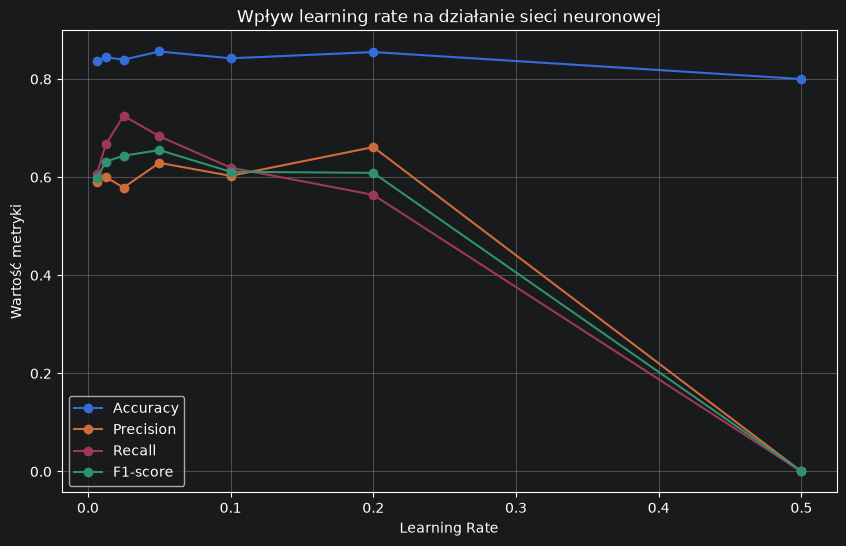

In [10]:
dane= dane.sort_values("Learning Rate")

plt.figure(figsize=(10, 6))

for metryka in ["Accuracy", "Precision", "Recall", "F1-score"]:
    plt.plot(
        dane["Learning Rate"],
        dane[metryka],
        marker="o",
        label=metryka
    )

plt.xlabel("Learning Rate")
plt.ylabel("Wartość metryki")
plt.title("Wpływ learning rate na działanie sieci neuronowej")

plt.legend()
plt.grid(True)
plt.show()